Задача 1: Катер с разряжающейся батареей

In [23]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

In [24]:
# Объявляем переменные и параметры
t = sp.symbols('t', positive=True)
z = sp.Function('z')(t)
tau = sp.symbols('tau', positive=True)

In [25]:
m = 1
k = 1
P0 = 1
v0 = 1
z0 = v0**2

In [27]:
ode_z = sp.Eq(z.diff(t) + 2 * (k / m) * z, 2 * (P0 / m) * sp.exp(-t / tau))
ode_z


Eq(2.0*z(t) + Derivative(z(t), t), 2.0*exp(-t/tau))

In [28]:
sol_z = sp.dsolve(ode_z, z, ics={z.subs(t, 0): z0})
sol_z

Eq(z(t), 2.0*tau*exp(-t/tau)/(2.0*tau - 1.0) - exp(-2.0*t)/(2.0*tau - 1.0))

In [29]:
print("Аналитическое решение уравнения:")
display(sol)

Аналитическое решение уравнения:


[]

In [30]:
v_expr = sp.sqrt(sol_z.rhs)

In [31]:
print("Аналитическое решение для v(t), полученное через dsolve:")
display(sp.Eq(sp.Function('v')(t), v_expr))


Аналитическое решение для v(t), полученное через dsolve:


Eq(v(t), sqrt(2.0*tau*exp(-t/tau)/(2.0*tau - 1.0) - exp(-2.0*t)/(2.0*tau - 1.0)))

In [32]:
calc_v = sp.lambdify((t, tau), v_expr, modules=['numpy'])

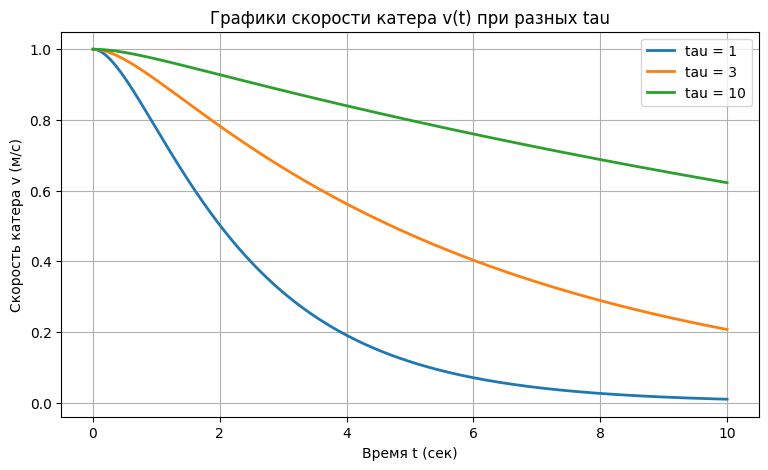

In [36]:
t_space = np.linspace(0, 10, 500)

plt.figure(figsize=(9, 5))

tau_values = np.array([1, 3, 10])

for tau_val in tau_values:
    v_space = calc_v(t_space, tau_val)
    plt.plot(t_space, v_space, label='tau = ' + str(tau_val), linewidth=2)

plt.title('Графики скорости катера v(t) при разных tau')
plt.xlabel('Время t (сек)')
plt.ylabel('Скорость катера v (м/с)')
plt.grid(True)
plt.legend()
plt.show()

Задача 2: Популяция в линейно ухудшающей среде

In [52]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

In [53]:
t_sym = sp.symbols('t', positive=True)
N_func = sp.Function('N')(t_sym)

In [54]:
a_sym, b_sym, c_sym, N0_sym = sp.symbols('a b c N0', positive=True)


In [55]:
ode = sp.Eq(N_func.diff(t_sym) - (a_sym - b_sym * t_sym) * N_func, -c_sym * N_func**2)
ode

Eq(-(a - b*t)*N(t) + Derivative(N(t), t), -c*N(t)**2)

In [56]:
sol = sp.dsolve(ode, N_func, ics={N_func.subs(t_sym, 0): N0_sym})
sol

Eq(N(t), 2*sqrt(b)*exp(t*(a - b*t/2))/(sqrt(b)*(sqrt(2)*sqrt(pi)*c*exp(a**2/(2*b))*erf(sqrt(2)*a/(2*sqrt(b)))/sqrt(b) + 2/N0) - sqrt(2)*sqrt(pi)*c*exp(a**2/(2*b))*erf(sqrt(2)*(a - b*t)/(2*sqrt(b)))))

In [57]:
print("Аналитическое решение")
display(sol)

Аналитическое решение


Eq(N(t), 2*sqrt(b)*exp(t*(a - b*t/2))/(sqrt(b)*(sqrt(2)*sqrt(pi)*c*exp(a**2/(2*b))*erf(sqrt(2)*a/(2*sqrt(b)))/sqrt(b) + 2/N0) - sqrt(2)*sqrt(pi)*c*exp(a**2/(2*b))*erf(sqrt(2)*(a - b*t)/(2*sqrt(b)))))

In [58]:
calc_N = sp.lambdify((t_sym, a_sym, b_sym, c_sym, N0_sym), sol.rhs, modules=['numpy'])

In [60]:
t_space = np.linspace(0, 20, 500)

a_val = 1.0
b_val = 0.1
c_val = 0.2
N0_val = 2.0

plt.figure(figsize=(10, 5))

N_space_main = calc_N(t_space, a_val, b_val, c_val, N0_val)
plt.plot(t_space, N_space_main, label='Основной случай ($b=0.1, c=0.2$)', color='red', linewidth=2)

N_space_b0 = calc_N(t_space, a_val, 1e-4, c_val, N0_val)
plt.plot(t_space, N_space_b0, label='Предел $b \\to 0$ (Стабильная среда)', color='blue', linestyle='--')

N_space_c0 = calc_N(t_space, a_val, b_val, 1e-4, N0_val)
plt.plot(t_space, N_space_c0, label='Предел $c \\to 0$ (Без конкуренции)', color='green', linestyle=':')

t_peak = a_val / b_val
plt.axvline(x=t_peak, color='gray', linestyle='-.', label=f'Время пика t* = {t_peak} мин')

plt.title('Динамика численности популяции N(t)')
plt.xlabel('Время t')
plt.ylabel('Численность N(t)')
plt.ylim(0, max(N_space_main) * 1.5)
plt.grid(True)
plt.legend()
plt.show()

TypeError: only length-1 arrays can be converted to Python scalars

<Figure size 1000x500 with 0 Axes>